<a href="https://colab.research.google.com/github/lewinskie254/stock-market-prediction/blob/main/predict_stock_prices_NeuralNets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [363]:
!pip install pytorch_forecasting pytorch_lightning

In [364]:
import numpy as np
import pandas as pd
import yfinance as yf
import torch
import torch.nn as nn
from tqdm.notebook import tqdm, trange
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from pytorch_forecasting.data.timeseries._timeseries import TimeSeriesDataSet
import pytorch_lightning as pl
from pytorch_lightning.callbacks import EarlyStopping, LearningRateMonitor
from pytorch_lightning.loggers import TensorBoardLogger
from pytorch_forecasting import Baseline, TemporalFusionTransformer, TimeSeriesDataSet
from pytorch_forecasting.data import GroupNormalizer
from pytorch_forecasting.metrics import SMAPE, PoissonLoss, QuantileLoss
from pytorch_forecasting.models.temporal_fusion_transformer.tuning import optimize_hyperparameters
import matplotlib.pyplot as plt

In [365]:
ticker = "AAPL"
stock = yf.Ticker(ticker)

# Get historical market data (e.g., past 1 year, daily interval)
hist = stock.history(period="1y", interval="1h")
print(hist.head())

# Get basic company info / metadata
info = stock.info
print(info.get("longName"), info.get("regularMarketPrice"))

# Get dividends and stock splits
dividends = stock.dividends
splits = stock.splits

                                 Open        High         Low       Close  \
Datetime                                                                    
2025-11-07 09:30:00-05:00  269.795013  272.290009  267.269989  271.579987   
2025-11-07 10:30:00-05:00  271.559998  271.970001  269.480011  269.529999   
2025-11-07 11:30:00-05:00  269.519989  269.890015  268.320007  269.109985   
2025-11-07 12:30:00-05:00  269.114990  269.140015  268.058807  268.450012   
2025-11-07 13:30:00-05:00  268.450012  268.660004  267.095001  267.250000   

                            Volume  Dividends  Stock Splits  
Datetime                                                     
2025-11-07 09:30:00-05:00  7855390        0.0           0.0  
2025-11-07 10:30:00-05:00  3991205        0.0           0.0  
2025-11-07 11:30:00-05:00  3276263        0.0           0.0  
2025-11-07 12:30:00-05:00  2041690        0.0           0.0  
2025-11-07 13:30:00-05:00  2217548        0.0           0.0  
Apple Inc. 342.37


In [366]:
hist.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits
Datetime,,,,,,,
2025-11-07 09:30:00-05:00,269.795013,272.290009,267.269989,271.579987,7855390,0.0,0.0
2025-11-07 10:30:00-05:00,271.559998,271.970001,269.480011,269.529999,3991205,0.0,0.0
2025-11-07 11:30:00-05:00,269.519989,269.890015,268.320007,269.109985,3276263,0.0,0.0
2025-11-07 12:30:00-05:00,269.114990,269.140015,268.058807,268.450012,2041690,0.0,0.0
2025-11-07 13:30:00-05:00,268.450012,268.660004,267.095001,267.250000,2217548,0.0,0.0


In [367]:
data = hist.drop(columns= ['Dividends', 'Stock Splits'])

In [368]:
data["year"] = data.index.year
data["month"] = data.index.month
data["day"] = data.index.dayofweek
data["date"] = data.index.day
data["hour"] = data.index.hour
data["cos_hour"] = np.cos(data.index.hour / 60 * 2 * np.pi)
data["sin_hour"] = np.sin(data.index.hour / 60 * 2 * np.pi)

In [369]:
data.index[:20]

DatetimeIndex(['2025-11-07 09:30:00-05:00', '2025-11-07 10:30:00-05:00',
               '2025-11-07 11:30:00-05:00', '2025-11-07 12:30:00-05:00',
               '2025-11-07 13:30:00-05:00', '2025-11-07 14:30:00-05:00',
               '2025-11-07 15:30:00-05:00', '2025-11-10 09:30:00-05:00',
               '2025-11-10 10:30:00-05:00', '2025-11-10 11:30:00-05:00',
               '2025-11-10 12:30:00-05:00', '2025-11-10 13:30:00-05:00',
               '2025-11-10 14:30:00-05:00', '2025-11-10 15:30:00-05:00',
               '2025-11-11 09:30:00-05:00', '2025-11-11 10:30:00-05:00',
               '2025-11-11 11:30:00-05:00', '2025-11-11 12:30:00-05:00',
               '2025-11-11 13:30:00-05:00', '2025-11-11 14:30:00-05:00'],
              dtype='datetime64[ns, America/New_York]', name='Datetime', freq=None)

In [370]:
train = data.iloc[:int(len(data) * 0.7)]
test = data.iloc[int(len(data) * 0.7):int(len(data) * 0.85)]
val = data.iloc[int(len(data) * 0.85):]

In [371]:
from sklearn.preprocessing import StandardScaler

features = ["Open", "High", "Low", "Volume"]

scaler = StandardScaler()

train[features] = scaler.fit_transform(train[features])

val[features] = scaler.transform(val[features])

test[features] = scaler.transform(test[features])

/tmp/ipykernel_9792/3278748688.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train[features] = scaler.fit_transform(train[features])
/tmp/ipykernel_9792/3278748688.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  val[features] = scaler.transform(val[features])
/tmp/ipykernel_9792/3278748688.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.py

In [372]:
X_train

In [373]:
train

,Open,High,Low,Close,Volume,year,month,day,date,hour,cos_hour,sin_hour
Datetime,,,,,,,,,,,,
2025-11-07 09:30:00-05:00,-0.387571,-0.314673,-0.462442,271.579987,1.132407,2025,11,4,7,9,5.877853e-01,0.809017
2025-11-07 10:30:00-05:00,-0.303453,-0.329820,-0.356750,269.529999,-0.135122,2025,11,4,7,10,5.000000e-01,0.866025
2025-11-07 11:30:00-05:00,-0.400678,-0.428277,-0.412226,269.109985,-0.369637,2025,11,4,7,11,4.067366e-01,0.913545
2025-11-07 12:30:00-05:00,-0.419980,-0.463779,-0.424717,268.450012,-0.774602,2025,11,4,7,12,3.090170e-01,0.951057
2025-11-07 13:30:00-05:00,-0.451673,-0.486500,-0.470811,267.250000,-0.716917,2025,11,4,7,13,2.079117e-01,0.978148
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-07-23 14:30:00-04:00,2.018273,2.000503,2.047851,320.419891,-0.211686,2026,7,3,23,14,1.045285e-01,0.994522
2026-07-23 15:30:00-04:00,2.023277,2.037425,2.061241,321.609985,-0.039828,2026,7,3,23,15,6.123234e-17,1.000000
2026-07-24 09:30:00-04:00,2.102392,2.390499,2.136803,328.799988,1.367160,2026,7,4,24,9,5.877853e-01,0.809017


In [374]:
train.shape

(1218, 12)

In [375]:
class DataWindow():
  def __init__(self, input_width, label_width, shift,train_df=train, val_df=val, test_df=test, label_columns=None):
    self.train_df = train_df
    self.val_df = val_df
    self.test_df = test_df
    self.label_columns = label_columns
    if label_columns is not None:
      self.label_columns_indices = {name: i for i, name in enumerate(label_columns)}
    self.column_indices = {name: i for i, name in enumerate(train_df.columns)}
    self.input_width = input_width
    self.label_width = label_width
    self.shift = shift
    self.total_window_size = input_width + shift
    self.input_slice = slice(0, input_width)
    self.input_indices =  np.arange(self.total_window_size)[self.input_slice]
    self.label_start = self.total_window_size - self.label_width
    self.labels_slice = slice(self.label_start, None)
    self.label_indices =np.arange(self.total_window_size)[self.labels_slice]

  def split_to_inputs_labels(self, features):
    inputs = features[:, self.input_slice, :]
    labels = features[:, self.labels_slice, :]
    if self.label_columns is not None:
      labels = torch.stack([labels[:,:,self.column_indices[name]] for name in  self.label_columns],axis=-1)
    inputs.set_shape([None, self.input_width, None])
    labels.set_shape([None, self.label_width, None])
    return inputs, labels

    def make_dataset(self, data):
      data = np.array(data, dtype=np.float32)
      ds = tf.keras.preprocessing.timeseries_dataset_from_array(
        data=data,
        targets=None,
        sequence_length=self.total_window_size,
        sequence_stride=1,
        shuffle=True,
        batch_size=32
      )
      ds = ds.map(self.split_to_inputs_labels)
      return ds

In [376]:
class WindowDataset(Dataset):
    def __init__(self, data, input_width, label_width, shift, label_columns=None):
        super().__init__()
        # Convert dataframe to a float32 tensor
        self.data = torch.as_tensor(data.to_numpy(dtype="float32"),dtype=torch.float32)
        self.input_width = input_width
        self.label_width = label_width
        self.shift = shift
        self.total_window_size = input_width + shift
        self.label_start = self.total_window_size - label_width

        # Map column names to their tensor indices
        self.column_indices = { name: i for i, name in enumerate(data.columns)}
        self.label_columns = label_columns

        if label_columns is not None:
            self.label_columns_indices = [ self.column_indices[name] for name in label_columns]
        else:
            self.label_columns_indices = None

    def __len__(self):
        return len(self.data) - self.total_window_size + 1

    def __getitem__(self, index):
        # Extract the complete time window
        window = self.data[index : index + self.total_window_size]
        # Separate inputs and labels
        inputs = window[:self.input_width]
        labels = window[self.label_start:]
        # Select specific target columns if provided
        if self.label_columns_indices is not None:
            labels = labels[:, self.label_columns_indices]

        return inputs, labels

In [377]:
class DataWindow:
    def __init__(self,input_width=7,label_width=1,shift=1,train_df=train,val_df=val,test_df=test,label_columns=['Close']):

        self.train_df = train_df
        self.val_df = val_df
        self.test_df = test_df

        self.input_width = input_width
        self.label_width = label_width
        self.shift = shift
        self.label_columns = label_columns

        self.total_window_size = input_width + shift
        self.input_slice = slice(0, input_width)
        self.label_start = self.total_window_size - label_width
        self.labels_slice = slice(self.label_start, None)

        self.column_indices = {name: i for i, name in enumerate(train_df.columns)}
        self.label_columns_indices = {name: i for i, name in enumerate(label_columns)} if label_columns is not None else None

        self.input_indices = np.arange(self.total_window_size)[:input_width]
        self.label_indices = np.arange(self.total_window_size)[self.label_start:]

    def make_dataset(self, data, batch_size=32, shuffle=False):
        dataset = WindowDataset(
            data=data,
            input_width=self.input_width,
            label_width=self.label_width,
            shift=self.shift,
            label_columns=self.label_columns
        )

        return DataLoader(dataset,batch_size=batch_size,shuffle=shuffle,drop_last=False)


    def plot(self, model=None, plot_col='Close', max_subplots=3):
        inputs, labels = self.sample_batch
        plot_col_index = self.column_indices[plot_col]

        # Find the target column's position in the labels tensor
        if self.label_columns is not None:
            label_col_index = self.label_columns_indices.get(plot_col)
        else:
            label_col_index = plot_col_index

        max_n = min(max_subplots, len(inputs))
        plt.figure(figsize=(12, 8))

        for n in range(max_n):
            plt.subplot(max_n, 1, n + 1)
            plt.ylabel(f'{plot_col} [scaled]')
            # Plot historical inputs
            plt.plot(self.input_indices,inputs[n, :, plot_col_index].cpu().numpy(),label='Inputs',marker='.')

            # Plot actual labels, if this feature is a target
            if label_col_index is not None:
                plt.scatter(self.label_indices,labels[n, :, label_col_index].cpu().numpy(),edgecolors='k',marker='s',label='Labels',c='green',s=64)
                # Plot predictions
                if model is not None:
                    model.eval()
                    device = next(model.parameters()).device
                    print("inputs shape", inputs.shape)
                    print("inputs closes", inputs[n, :, plot_col_index])
                    with torch.no_grad():
                        predictions = model(
                            inputs.to(device).flatten(start_dim=1)
                        )
                    predictions = predictions.reshape(-1, self.label_width, len(self.label_columns))
                    print(f"prediction {n, }", predictions[n])
                    plt.scatter(self.label_indices,predictions[n, :, label_col_index].cpu().numpy(),marker='X',edgecolors='k',label='Predictions',c='red',s=64)
            if n == 0:
                plt.legend()
            plt.xlabel('Time steps')
        plt.tight_layout()
        plt.show()



    @property
    def train(self):
        return self.make_dataset(self.train_df, shuffle=True)

    @property
    def val(self):
        return self.make_dataset(self.val_df)

    @property
    def test(self):
        return self.make_dataset(self.test_df)

    @property
    def sample_batch(self):
        result = next(iter(self.train))
        self.sample = result
        return self.sample


In [378]:
hourly_window = DataWindow()

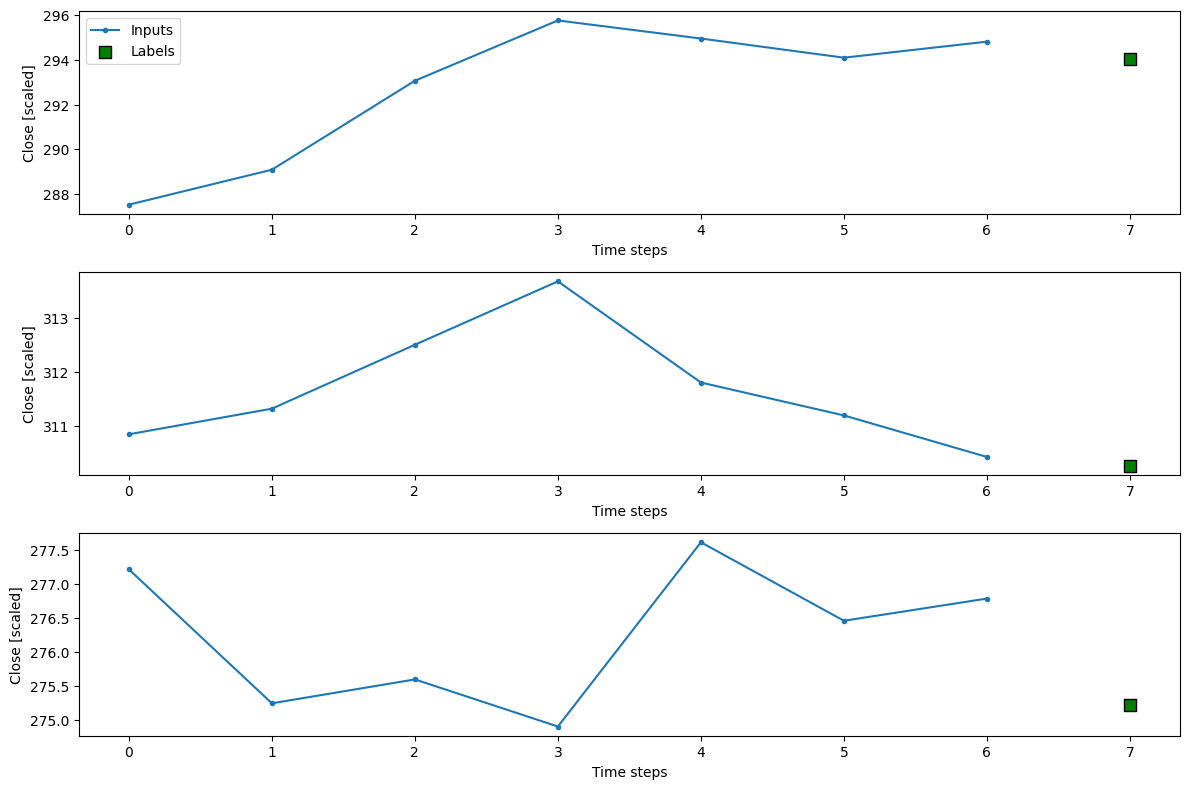

In [379]:
hourly_window.plot()

In [380]:
input_width = 7
label_width = 1

In [394]:
model = nn.Sequential(
    nn.Flatten(start_dim=1),
    nn.Linear(7 * 12, 50),
    nn.ReLU(),
    nn.Linear(50, label_width)
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

inputs shape torch.Size([32, 7, 12])
inputs closes tensor([278.8014, 278.7900, 277.5600, 277.4600, 277.2300, 276.9700, 276.3600])
prediction (0,) tensor([[-97.3912]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([311.3600, 310.4705, 309.1850, 309.8300, 308.3799, 308.3800, 311.2600])
prediction (1,) tensor([[-99.9123]])
inputs shape torch.Size([32, 7, 12])
inputs closes tensor([279.3450, 276.7250, 275.0500, 278.2600, 279.0300, 275.9000, 279.1950])
prediction (2,) tensor([[-98.0961]])


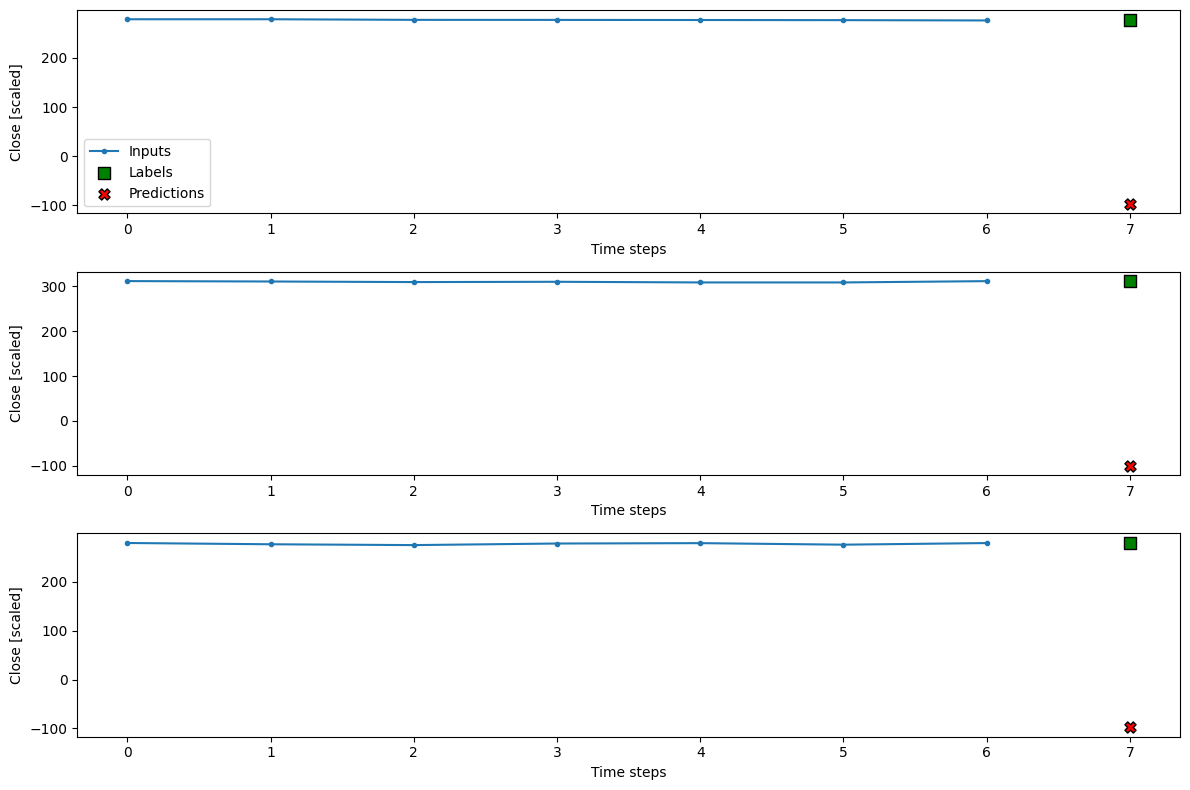

In [395]:
hourly_window.plot(model=model)

In [396]:

def train_loop(model, n_epochs, data_window, learning_rate):
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    train_loss = []
    val_loss = []

    for epoch in tqdm(range(n_epochs)):
        model.train()
        running_train_loss = 0.0

        for inputs, labels in data_window.train:
            optimizer.zero_grad()
            preds = model(inputs.flatten(start_dim=1))
            loss = loss_fn(preds, labels.squeeze(1))
            loss.backward()
            optimizer.step()
            running_train_loss += loss.item()
        epoch_train_loss = running_train_loss / len(data_window.train)
        train_loss.append(epoch_train_loss)

        # Validation
        model.eval()
        running_val_loss = 0.0

        with torch.no_grad():
            for inputs, labels in data_window.val:
                preds = model(inputs.flatten(start_dim=1))
                loss = loss_fn(preds, labels.squeeze(1))
                running_val_loss += loss.item()
        epoch_val_loss = running_val_loss / len(data_window.val)
        val_loss.append(epoch_val_loss)

        print(
            f"Epoch: {epoch + 1} | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f}"
        )

    return train_loss, val_loss

In [397]:
tl, vl = train_loop(model, 1000, hourly_window, 0.001)

  0%|          | 0/1000 [00:00<?, ?it/s]

Epoch: 1 | Train Loss: 18326.5639 | Val Loss: 4691.9329
Epoch: 2 | Train Loss: 551.8502 | Val Loss: 2927.6584
Epoch: 3 | Train Loss: 331.2005 | Val Loss: 2631.2032
Epoch: 4 | Train Loss: 293.8630 | Val Loss: 2374.9794
Epoch: 5 | Train Loss: 260.9767 | Val Loss: 2318.1754
Epoch: 6 | Train Loss: 231.6044 | Val Loss: 1689.4348
Epoch: 7 | Train Loss: 205.1408 | Val Loss: 1473.6567
Epoch: 8 | Train Loss: 177.9837 | Val Loss: 1335.2124
Epoch: 9 | Train Loss: 155.2992 | Val Loss: 1221.3167
Epoch: 10 | Train Loss: 133.1977 | Val Loss: 1287.8748
Epoch: 11 | Train Loss: 117.3339 | Val Loss: 941.4452
Epoch: 12 | Train Loss: 97.1380 | Val Loss: 697.2790
Epoch: 13 | Train Loss: 83.1330 | Val Loss: 637.2536
Epoch: 14 | Train Loss: 71.0745 | Val Loss: 478.4055
Epoch: 15 | Train Loss: 59.5064 | Val Loss: 463.7404
Epoch: 16 | Train Loss: 50.2235 | Val Loss: 384.4860
Epoch: 17 | Train Loss: 42.2312 | Val Loss: 301.0025
Epoch: 18 | Train Loss: 36.2816 | Val Loss: 225.0024
Epoch: 19 | Train Loss: 30.7234 

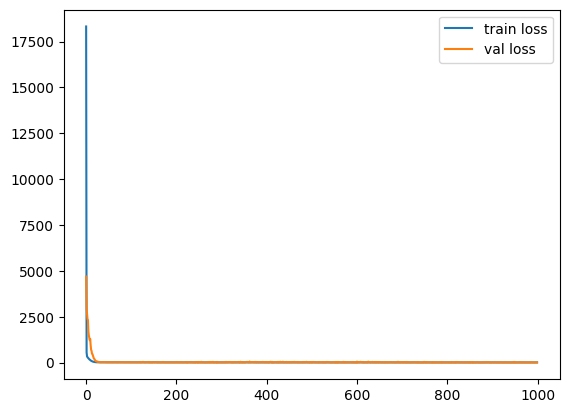

In [398]:
plt.plot(tl, label="train loss")
plt.plot(vl, label="val loss")
plt.legend()
plt.show()

In [399]:
model.eval()

predictions = []
actuals = []

with torch.inference_mode():
    for X, y in hourly_window.test:

        X = X.to(device)

        preds = model(X.flatten(start_dim=1))

        predictions.append(preds.cpu())
        actuals.append(y)

predictions = torch.cat(predictions, dim=0)
actuals = torch.cat(actuals, dim=0)

In [400]:
test_loss = nn.MSELoss()(predictions, actuals)
print(f"Test Loss: {test_loss:.4f}")

Test Loss: 242.3610


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:630: UserWarning: Using a target size (torch.Size([254, 1, 1])) that is different to the input size (torch.Size([254, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


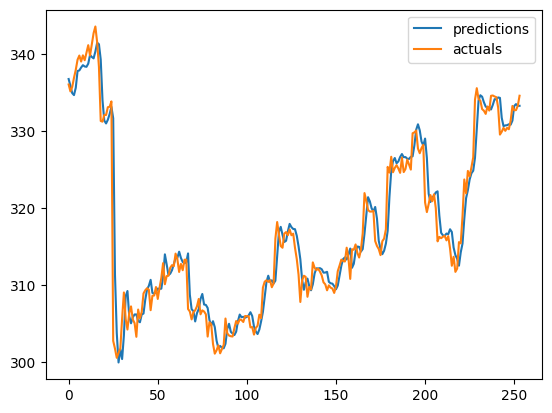

In [405]:
plt.plot(predictions.detach().numpy(), label="predictions")
plt.plot(actuals.squeeze(-1).squeeze(-1).detach().numpy(), label="actuals")
plt.legend()
plt.show()

In [392]:
len(test)

261